# Potato Disease Classification

### Import all the Dependencies

In [2]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt
import math

### Set all the Constants

In [3]:
BATCH_SIZE = 32
IMAGE_SIZE = 256
CHANNELS=3
EPOCHS=50

### Import data into TensorFlow Dataset object

In [5]:
dataset = tf.keras.utils.image_dataset_from_directory(
    "../dataset/PlantVillage",
    seed=123,
    shuffle=True,
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

Found 16011 files belonging to 10 classes.


In [6]:
class_names = dataset.class_names
class_names

['Tomato_Bacterial_spot',
 'Tomato_Early_blight',
 'Tomato_Late_blight',
 'Tomato_Leaf_Mold',
 'Tomato_Septoria_leaf_spot',
 'Tomato_Spider_mites_Two_spotted_spider_mite',
 'Tomato__Target_Spot',
 'Tomato__Tomato_YellowLeaf__Curl_Virus',
 'Tomato__Tomato_mosaic_virus',
 'Tomato_healthy']

In [7]:
for image_batch, label in dataset.take(1):
    print(image_batch.shape)
    print(label.numpy())

(32, 256, 256, 3)
[0 2 4 6 0 7 9 6 6 7 4 7 1 1 0 7 0 7 0 9 0 5 7 2 1 4 7 9 9 1 2 5]


### Visualize some of the images from our dataset

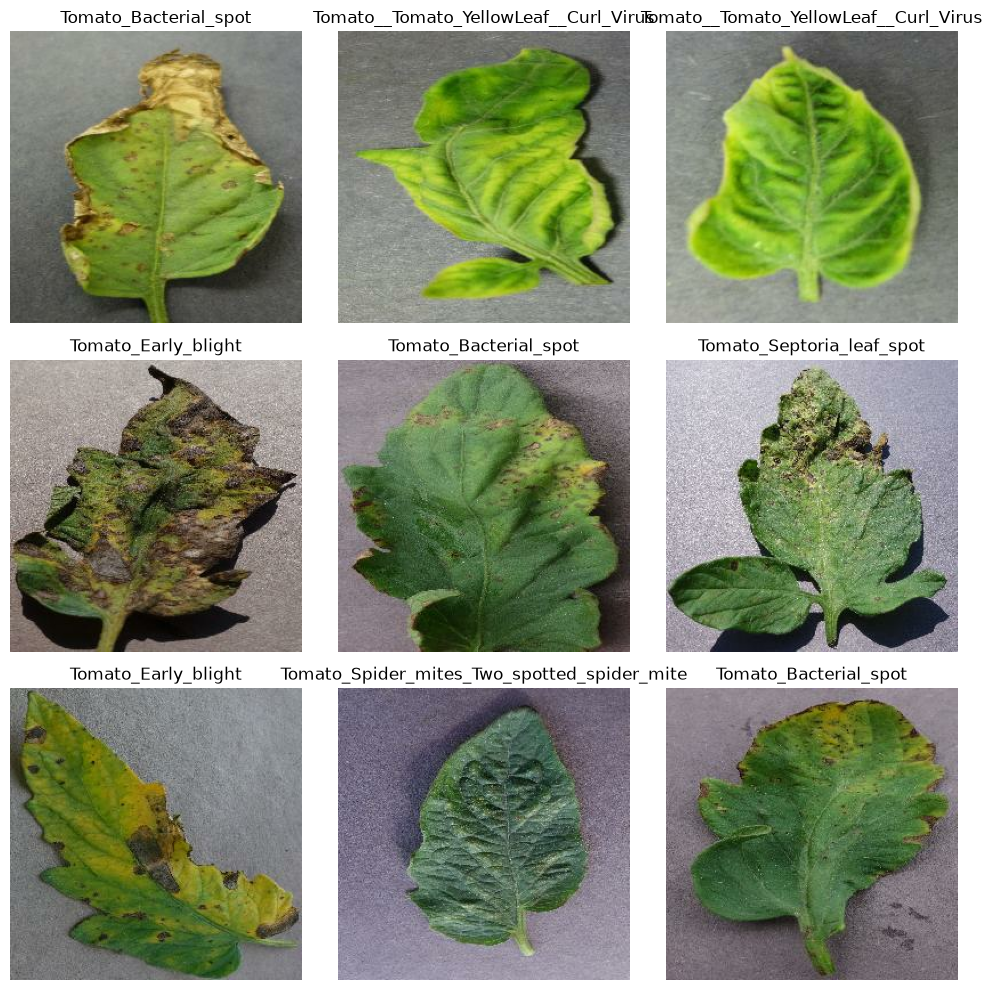

In [15]:
plt.figure(figsize=(10, 10))
for images, labels in dataset.take(1):
    for i in range(9):  # Display the first 9 images in the batch
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

### Function to Split Dataset

In [16]:
def three_way_split(
    ds,
    train_split=0.8,
    val_split=0.1,
    test_split=0.1,
    shuffle=True,
    shuffle_size=10000,
    seed=12
):
    assert math.isclose(
        train_split + val_split + test_split, 1.0
    ), "Split proportions must add up to 1."

    ds_size = int(ds.cardinality().numpy())

    if ds_size < 0:
        raise ValueError("Dataset cardinality is unknown or infinite.")

    if shuffle:
        ds = ds.shuffle(
            buffer_size=min(shuffle_size, ds_size*BATCH_SIZE),
            seed=seed,
            reshuffle_each_iteration=False
        )

    train_size = int(train_split * ds_size)
    val_size = int(val_split * ds_size)

    train_ds = ds.take(train_size)
    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size + val_size)

    return train_ds, val_ds, test_ds

In [17]:
train_ds, val_ds, test_ds = three_way_split(dataset)

In [18]:
len(train_ds), len(val_ds), len(test_ds)

(400, 50, 51)

### Cache, Shuffle, and Prefetch the Datasets

In [19]:
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

# Building the Model

### Creating a Layer for Resizing and Normalization

In [20]:
resize_rescale = tf.keras.Sequential([
  layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
  layers.Rescaling(1./255),
])

### Data Augmentation

In [21]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(
        height_factor=(-0.1, 0),
        width_factor=(-0.1, 0)
    ),
])